# 02. Визуализация и пространственная диагностика

Для каждого из четырех показателей: тематическая карта, описательная статистика, глобальная и локальная
пространственная автокорреляция. Затем — обоснование структуры соседства, анализ связи признаков
и выбор их преобразования для кластеризации.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
import esda
from libpysal.weights import KNN, Queen, DistanceBand
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src.common import PROCESSED, RESULTS, MAPS, FEATURES, LABELS, SHORT, SEED, connected_queen
from src.viz import choropleth, lisa_map, short_name, CAT, SEQ, INK2, MUTED, BLUE, RED

pd.set_option("display.width", 200)
np.random.seed(SEED)
gdf = gpd.read_file(PROCESSED / "regions_digital_2021.gpkg")
X = gdf[FEATURES]
print(gdf.shape, gdf.crs.name)

(85, 9) unknown


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Описательная статистика
Коэффициент вариации показывает относительный разброс; асимметрия и тест Шапиро–Уилка — близость к
нормальному распределению (важно для выбора меры расстояния и устойчивости k-средних к выбросам).

In [2]:
def describe(s):
    i_min, i_max = s.idxmin(), s.idxmax()
    return pd.Series({
        "среднее": s.mean(), "медиана": s.median(), "ст. откл.": s.std(), "CV, %": 100 * s.std() / s.mean(),
        "мин": s.min(), "регион (мин)": gdf.name[i_min], "макс": s.max(), "регион (макс)": gdf.name[i_max],
        "асимметрия": stats.skew(s), "эксцесс": stats.kurtosis(s), "Шапиро p": stats.shapiro(s).pvalue,
    })

desc = pd.DataFrame({SHORT[f]: describe(X[f]) for f in FEATURES}).T
desc.to_csv(RESULTS / "02_descriptive.csv", encoding="utf-8")
desc

,среднее,медиана,ст. откл.,"CV, %",мин,регион (мин),макс,регион (макс),асимметрия,эксцесс,Шапиро p
ПК,69.790588,68.3,9.354546,13.403736,45.7,Республика Марий Эл,95.7,Чукотский автономный округ,0.332272,0.519383,0.054264
Интернет,83.301176,82.0,6.187266,7.427585,72.0,Республика Марий Эл,98.5,Ямало-Ненецкий автономный округ,0.462489,-0.585404,0.014413
ШПД,81.796471,80.9,6.451125,7.886801,69.5,Новгородская область,98.4,Ямало-Ненецкий автономный округ,0.314183,-0.399495,0.368839
Ежедневно онлайн,79.752941,79.6,6.658124,8.348437,66.5,Тверская область,94.9,Ямало-Ненецкий автономный округ,0.319575,-0.513,0.145445


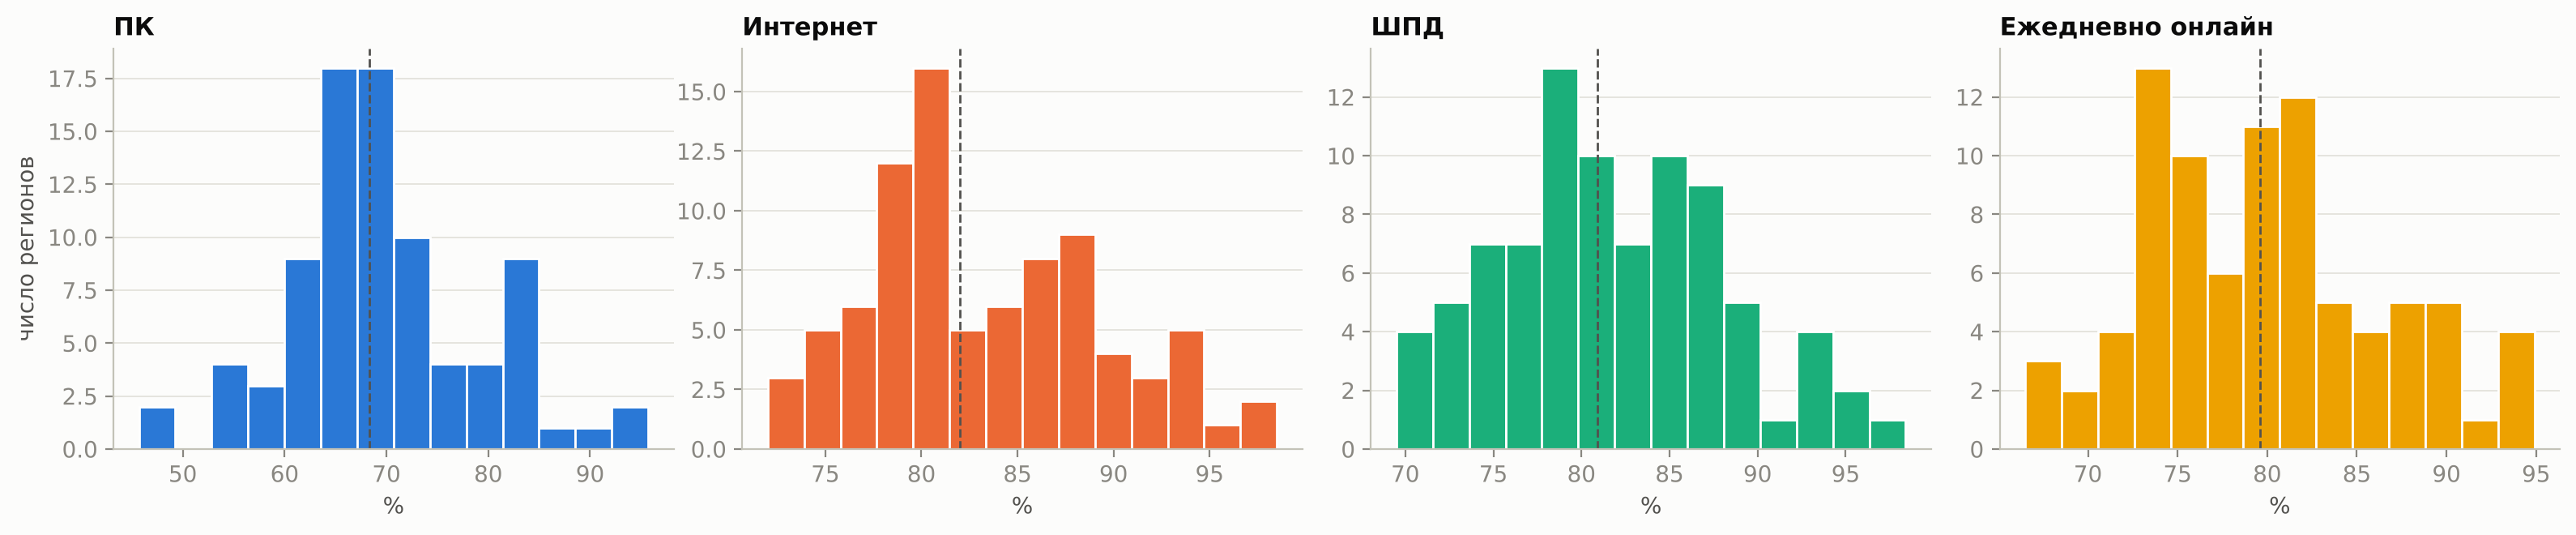

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4), sharey=False)
for a, f, c in zip(ax, FEATURES, CAT):
    a.hist(X[f], bins=14, color=c, edgecolor="#ffffff", linewidth=1)
    a.axvline(X[f].median(), color=INK2, lw=1, ls="--")
    a.set_title(SHORT[f], loc="left"); a.set_xlabel("%"); a.grid(axis="x", visible=False)
ax[0].set_ylabel("число регионов")
plt.tight_layout(); plt.savefig(MAPS / "02_histograms.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Тематические карты
Классы — естественные интервалы Фишера–Дженкса (k = 5): минимизируют дисперсию внутри классов и подходят
для неравномерных распределений лучше равных интервалов. В скобках — число регионов в классе.

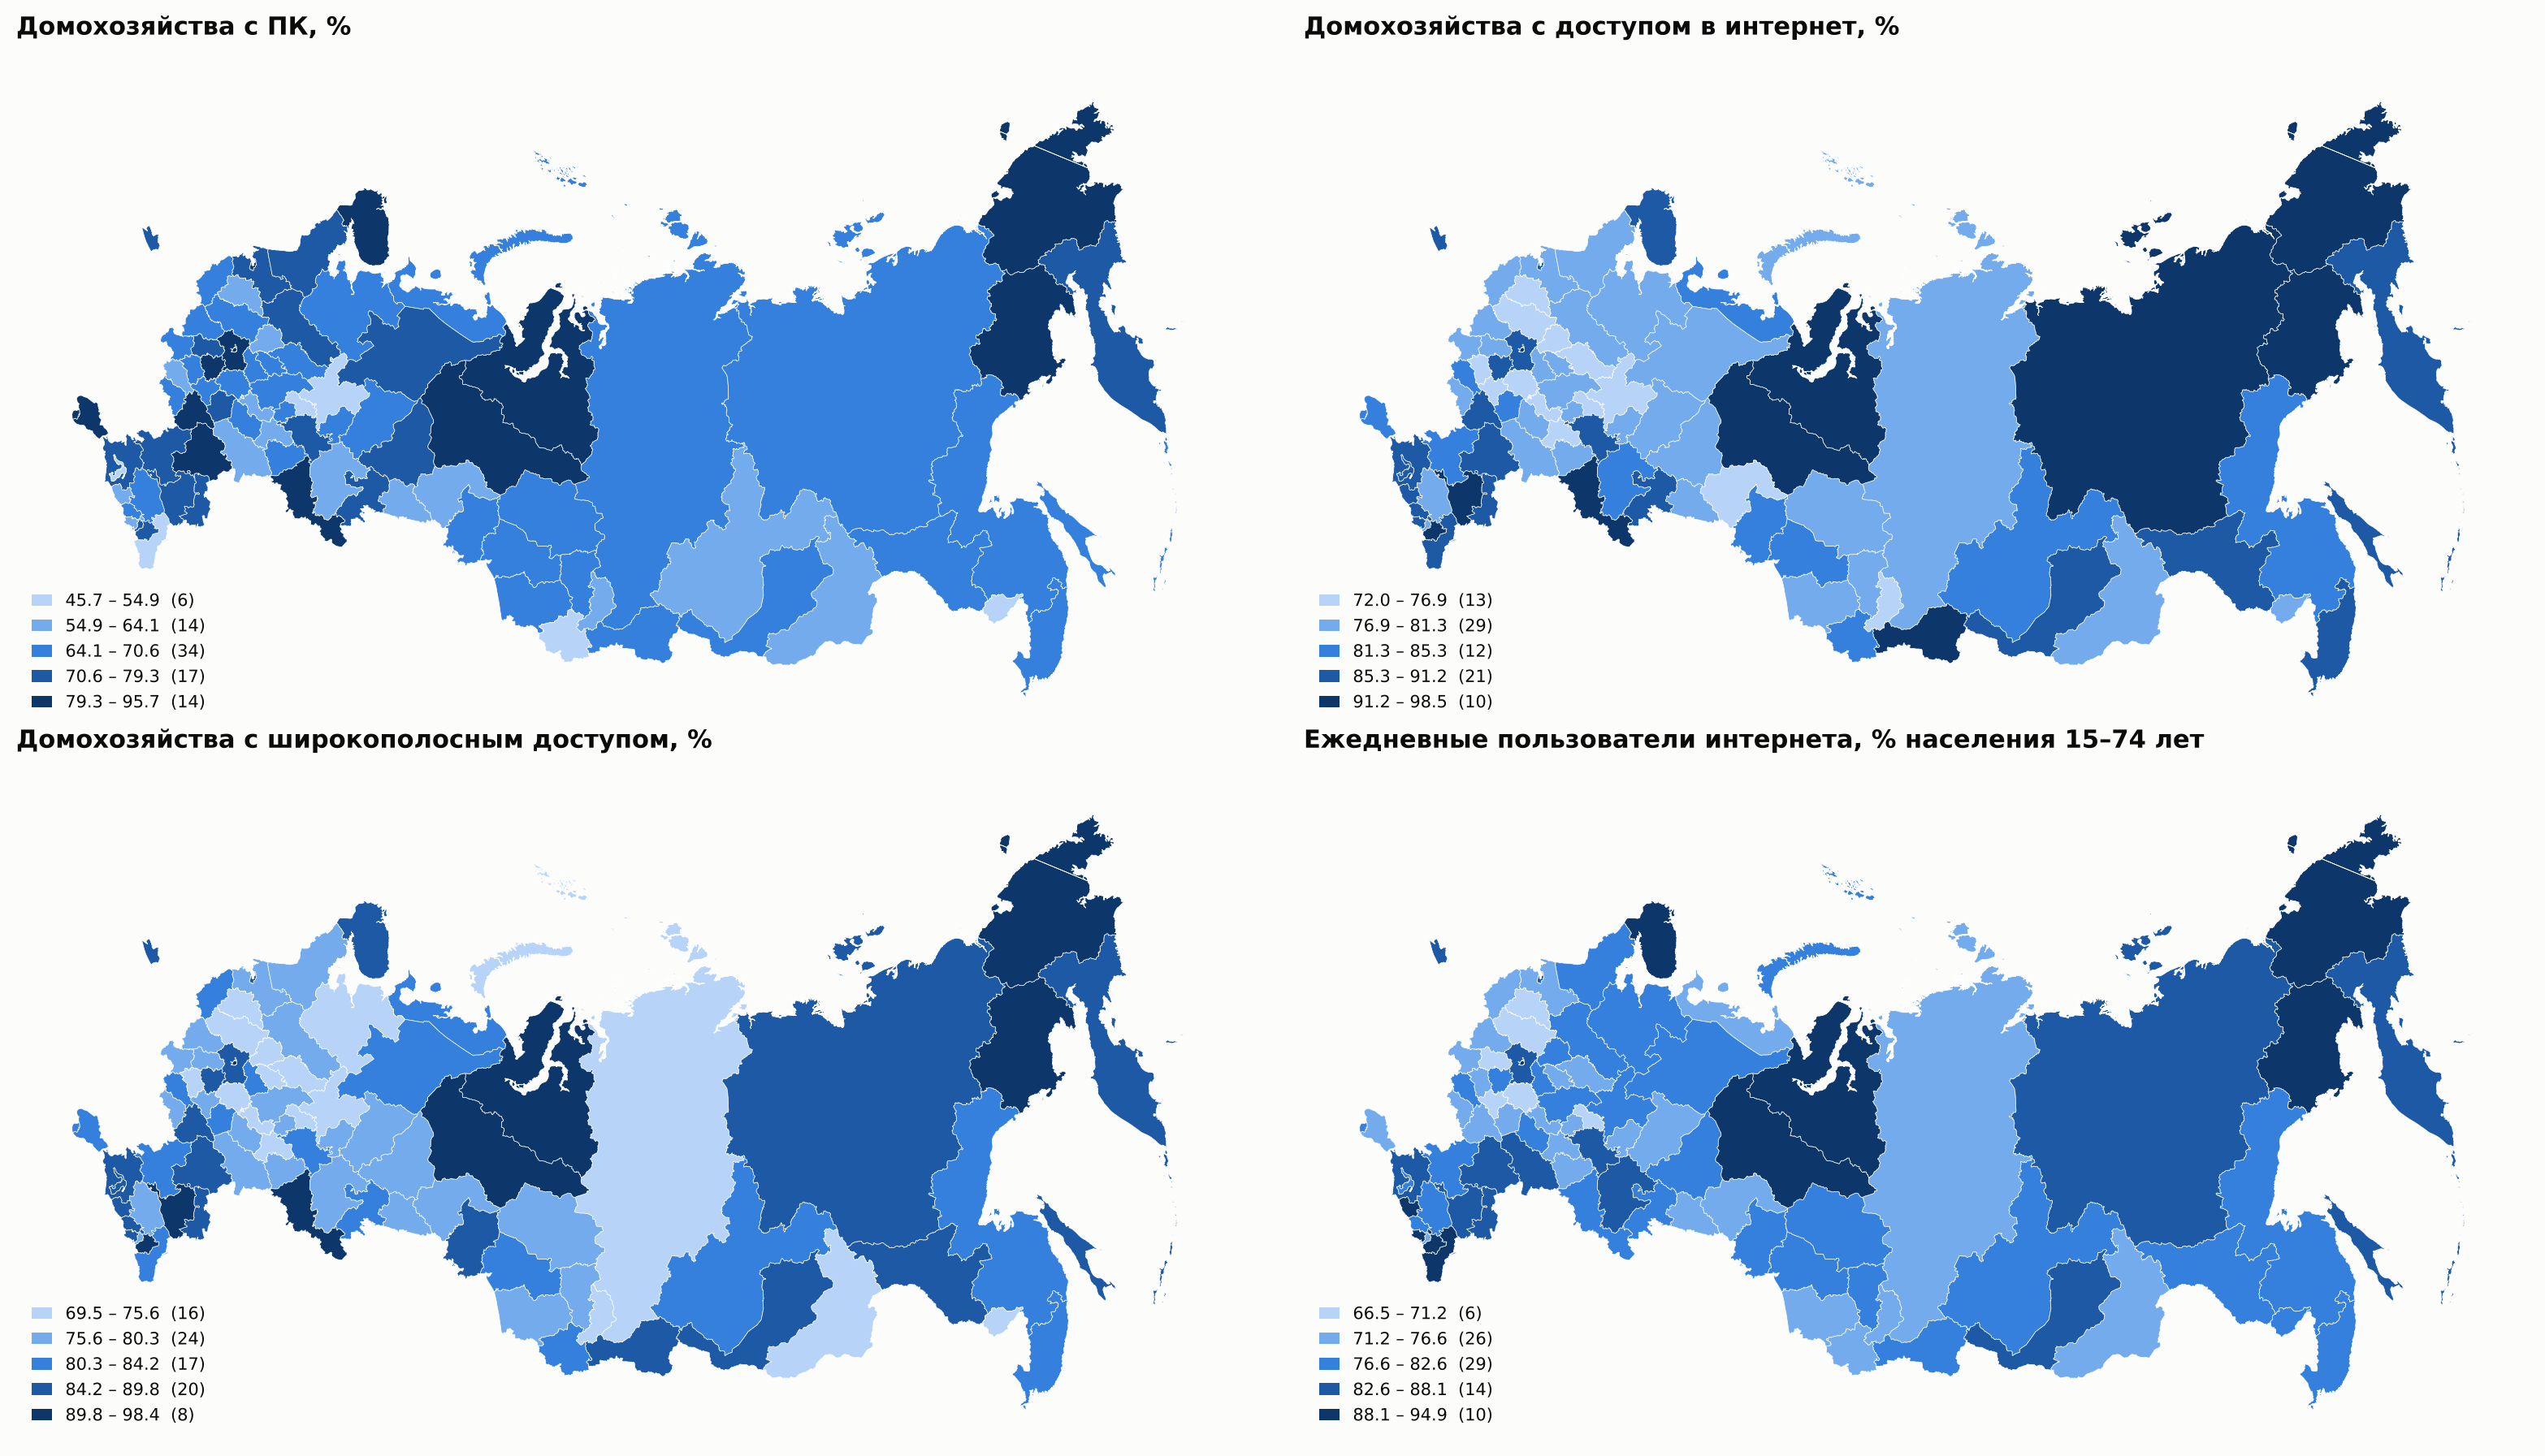

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, f in zip(axes.ravel(), FEATURES):
    choropleth(ax, gdf, f, k=5, title=LABELS[f])
plt.tight_layout(); plt.savefig(MAPS / "02_indicators_maps.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Структура соседства
Рассматриваются три представления пространственных отношений:
1. **Queen-смежность** (общая граница или вершина) — естественна для полигонов субъектов, отражает
   реальные транспортные, экономические и институциональные связи соседних регионов.
   Недостаток: изолированные регионы. Калининградская и Сахалинская области не граничат ни с одним субъектом,
   а Крым и Севастополь образуют отдельную компоненту (связь с Краснодарским краем — через Керченский пролив).
   Они присоединяются к ближайшему по расстоянию между границами региону (функция `connected_queen`).
2. **k ближайших соседей** (k = 4, 6) по центроидам — у всех одинаковое число соседей, но крупные регионы
   Сибири и Дальнего Востока «соседствуют» через тысячи километров.
3. **Диапазон расстояний** — плохо подходит: при порогах, связывающих Восток, у регионов европейской части
   десятки соседей.

In [5]:
w_queen_raw = Queen.from_dataframe(gdf, use_index=False, silence_warnings=True)
print("Queen: изолированные регионы:", [gdf.name[i] for i in w_queen_raw.islands],
      "| компонент связности:", w_queen_raw.n_components)
w, added = connected_queen(gdf)
for i, j, d in added:
    print(f"  добавлена связь: {gdf.name[i]} — {gdf.name[j]} ({d:.0f} км между границами)")
card = pd.Series(w.cardinalities)
print("число соседей: среднее", round(card.mean(), 2), "мин", card.min(), "макс", card.max(),
      "| регион с макс.:", gdf.name[card.idxmax()])

cent = gdf.geometry.centroid
pts = np.column_stack([cent.x, cent.y])
W = {"Queen + связи": w, "KNN k=4": KNN.from_array(pts, k=4), "KNN k=6": KNN.from_array(pts, k=6)}
thr = max(np.min([d for d in dist if d > 0]) for dist in np.linalg.norm(pts[:, None] - pts[None], axis=2))
W["Диапазон расстояний"] = DistanceBand.from_array(pts, threshold=thr * 1.0001, binary=True, silence_warnings=True)
print("порог диапазона (у каждого региона ≥1 сосед), км:", round(thr / 1000),
      "| соседей: от", min(W["Диапазон расстояний"].cardinalities.values()),
      "до", max(W["Диапазон расстояний"].cardinalities.values()))
for ww in W.values():
    ww.transform = "r"

Queen: изолированные регионы: ['Калининградская область', 'Сахалинская область'] | компонент связности: 4
  добавлена связь: Калининградская область — Псковская область (362 км между границами)
  добавлена связь: Сахалинская область — Хабаровский край (8 км между границами)
  добавлена связь: Республика Крым — Краснодарский край (1 км между границами)
число соседей: среднее 4.52 мин 1 макс 9 | регион с макс.: Кировская область
порог диапазона (у каждого региона ≥1 сосед), км: 1236 | соседей: от 1 до 52


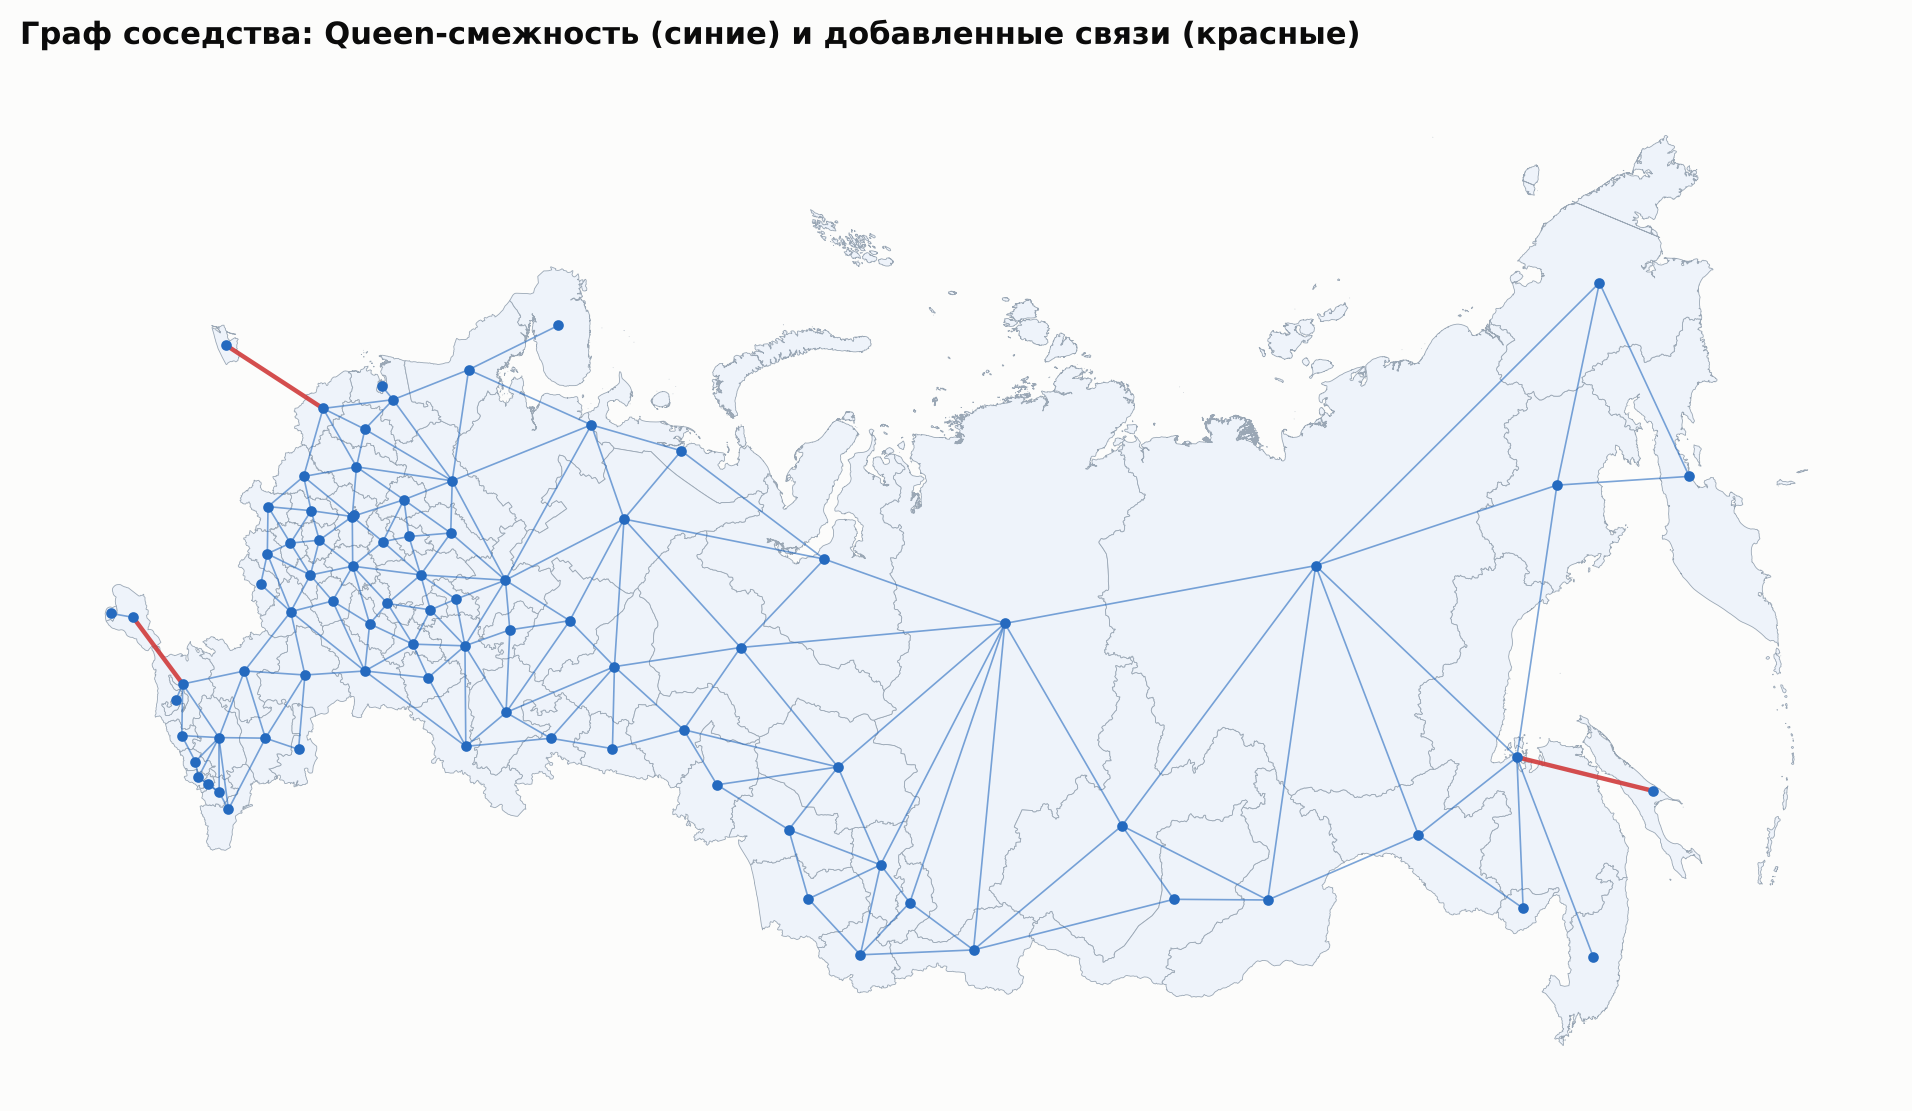

In [6]:
fig, ax = plt.subplots(figsize=(13, 6.5))
gdf.plot(ax=ax, color="#eef3fa", edgecolor="#9aa7b5", linewidth=0.3)
for i, nb in w.neighbors.items():
    for j in nb:
        if i < j:
            extra = (i, j) in {(a, b) for a, b, _ in added} or (j, i) in {(a, b) for a, b, _ in added}
            ax.plot([pts[i, 0], pts[j, 0]], [pts[i, 1], pts[j, 1]], color=RED if extra else BLUE,
                    lw=1.6 if extra else 0.6, alpha=0.9 if extra else 0.6)
ax.scatter(pts[:, 0], pts[:, 1], s=8, color=BLUE, zorder=3)
ax.set_axis_off(); ax.set_title("Граф соседства: Queen-смежность (синие) и добавленные связи (красные)", loc="left")
plt.savefig(MAPS / "02_neighbours_graph.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Глобальная пространственная автокорреляция
Индекс Морана $I=\frac{n}{S_0}\frac{\sum_i\sum_j w_{ij}z_iz_j}{\sum_i z_i^2}$ при $H_0$ (пространственная
случайность) имеет $E[I]=-1/(n-1)=-0{,}012$. Значимость — перестановочный тест (9 999 перестановок).
Дополнительно — индекс Гири $C$ (чувствителен к различиям именно между соседями; $C<1$ — положительная
автокорреляция). Сравнение по четырем матрицам весов показывает устойчивость вывода.

In [7]:
rows = []
for wname, ww in W.items():
    for f in FEATURES:
        mi = esda.Moran(X[f], ww, permutations=9999)
        gc = esda.Geary(X[f], ww, permutations=9999)
        rows.append({"матрица": wname, "показатель": SHORT[f], "I": mi.I, "z": mi.z_sim, "p (I)": mi.p_sim,
                     "C": gc.C, "p (C)": gc.p_sim})
moran = pd.DataFrame(rows)
moran.to_csv(RESULTS / "02_global_autocorrelation.csv", index=False, encoding="utf-8")
moran.pivot(index="показатель", columns="матрица", values="I").round(3)

матрица,KNN k=4,KNN k=6,Queen + связи,Диапазон расстояний
показатель,,,,
Ежедневно онлайн,0.238,0.176,0.249,0.113
Интернет,0.258,0.210,0.284,0.186
ПК,0.188,0.137,0.213,0.081
ШПД,0.139,0.112,0.165,0.083


In [8]:
moran.pivot(index="показатель", columns="матрица", values="p (I)").round(4)

матрица,KNN k=4,KNN k=6,Queen + связи,Диапазон расстояний
показатель,,,,
Ежедневно онлайн,0.0008,0.0023,0.0006,0.0059
Интернет,0.0002,0.0005,0.0002,0.0003
ПК,0.0046,0.0092,0.0030,0.0214
ШПД,0.0203,0.0242,0.0141,0.0193


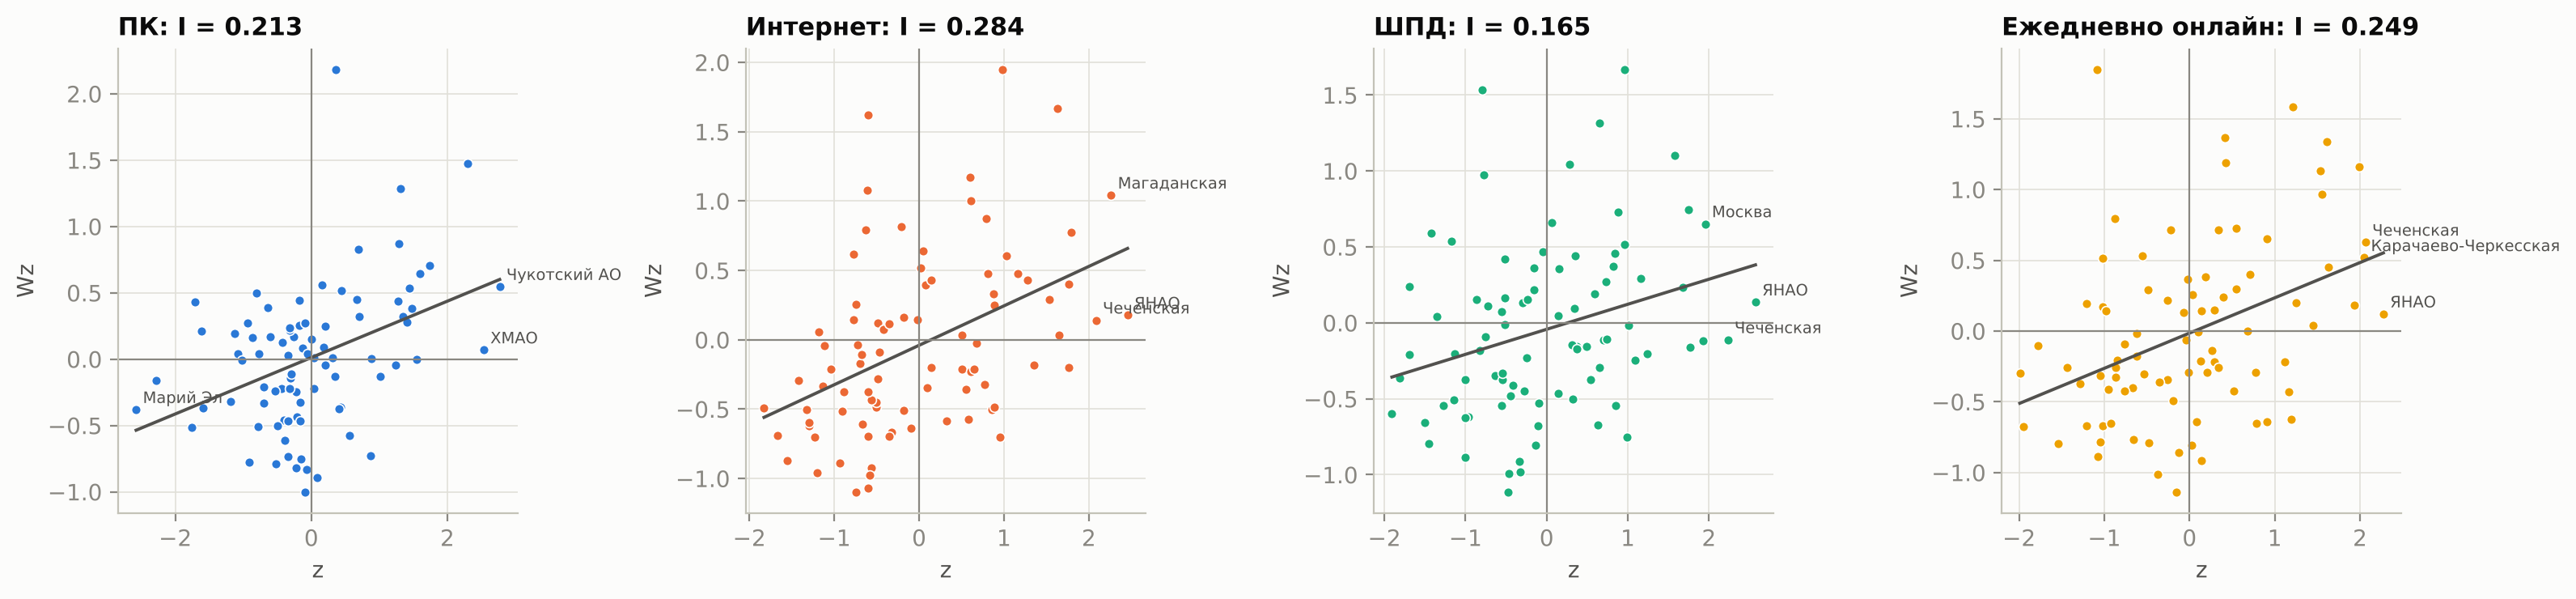

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, f, c in zip(axes, FEATURES, CAT):
    z = (X[f] - X[f].mean()) / X[f].std()
    lag = W["Queen + связи"].sparse @ z
    ax.scatter(z, lag, s=18, color=c, edgecolor="#ffffff", linewidth=0.6)
    b = np.polyfit(z, lag, 1)
    xs = np.linspace(z.min(), z.max(), 10)
    ax.plot(xs, b[0] * xs + b[1], color=INK2, lw=1.4)
    ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
    for k in np.argsort(-np.abs(z.to_numpy()))[:3]:
        ax.annotate(short_name(gdf.name[k]), (z.iloc[k], lag[k]), fontsize=7, color=INK2,
                    xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{SHORT[f]}: I = {b[0]:.3f}", loc="left"); ax.set_xlabel("z"); ax.set_ylabel("Wz")
plt.tight_layout(); plt.savefig(MAPS / "02_moran_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Локальная неоднородность: LISA и многомерный локальный индекс Гири
Локальный индекс Морана $I_i=\frac{z_i}{m_2}\sum_j w_{ij}z_j$ относит регион к кластеру High-High / Low-Low
или к выбросу High-Low / Low-High. Значимость — условные перестановки (9 999). При 85 тестах на
уровне 0,05 случайно ожидается ≈4 «значимых» региона, поэтому дополнительно приводится число значимых
после поправки FDR (Бенджамини–Хохберг).

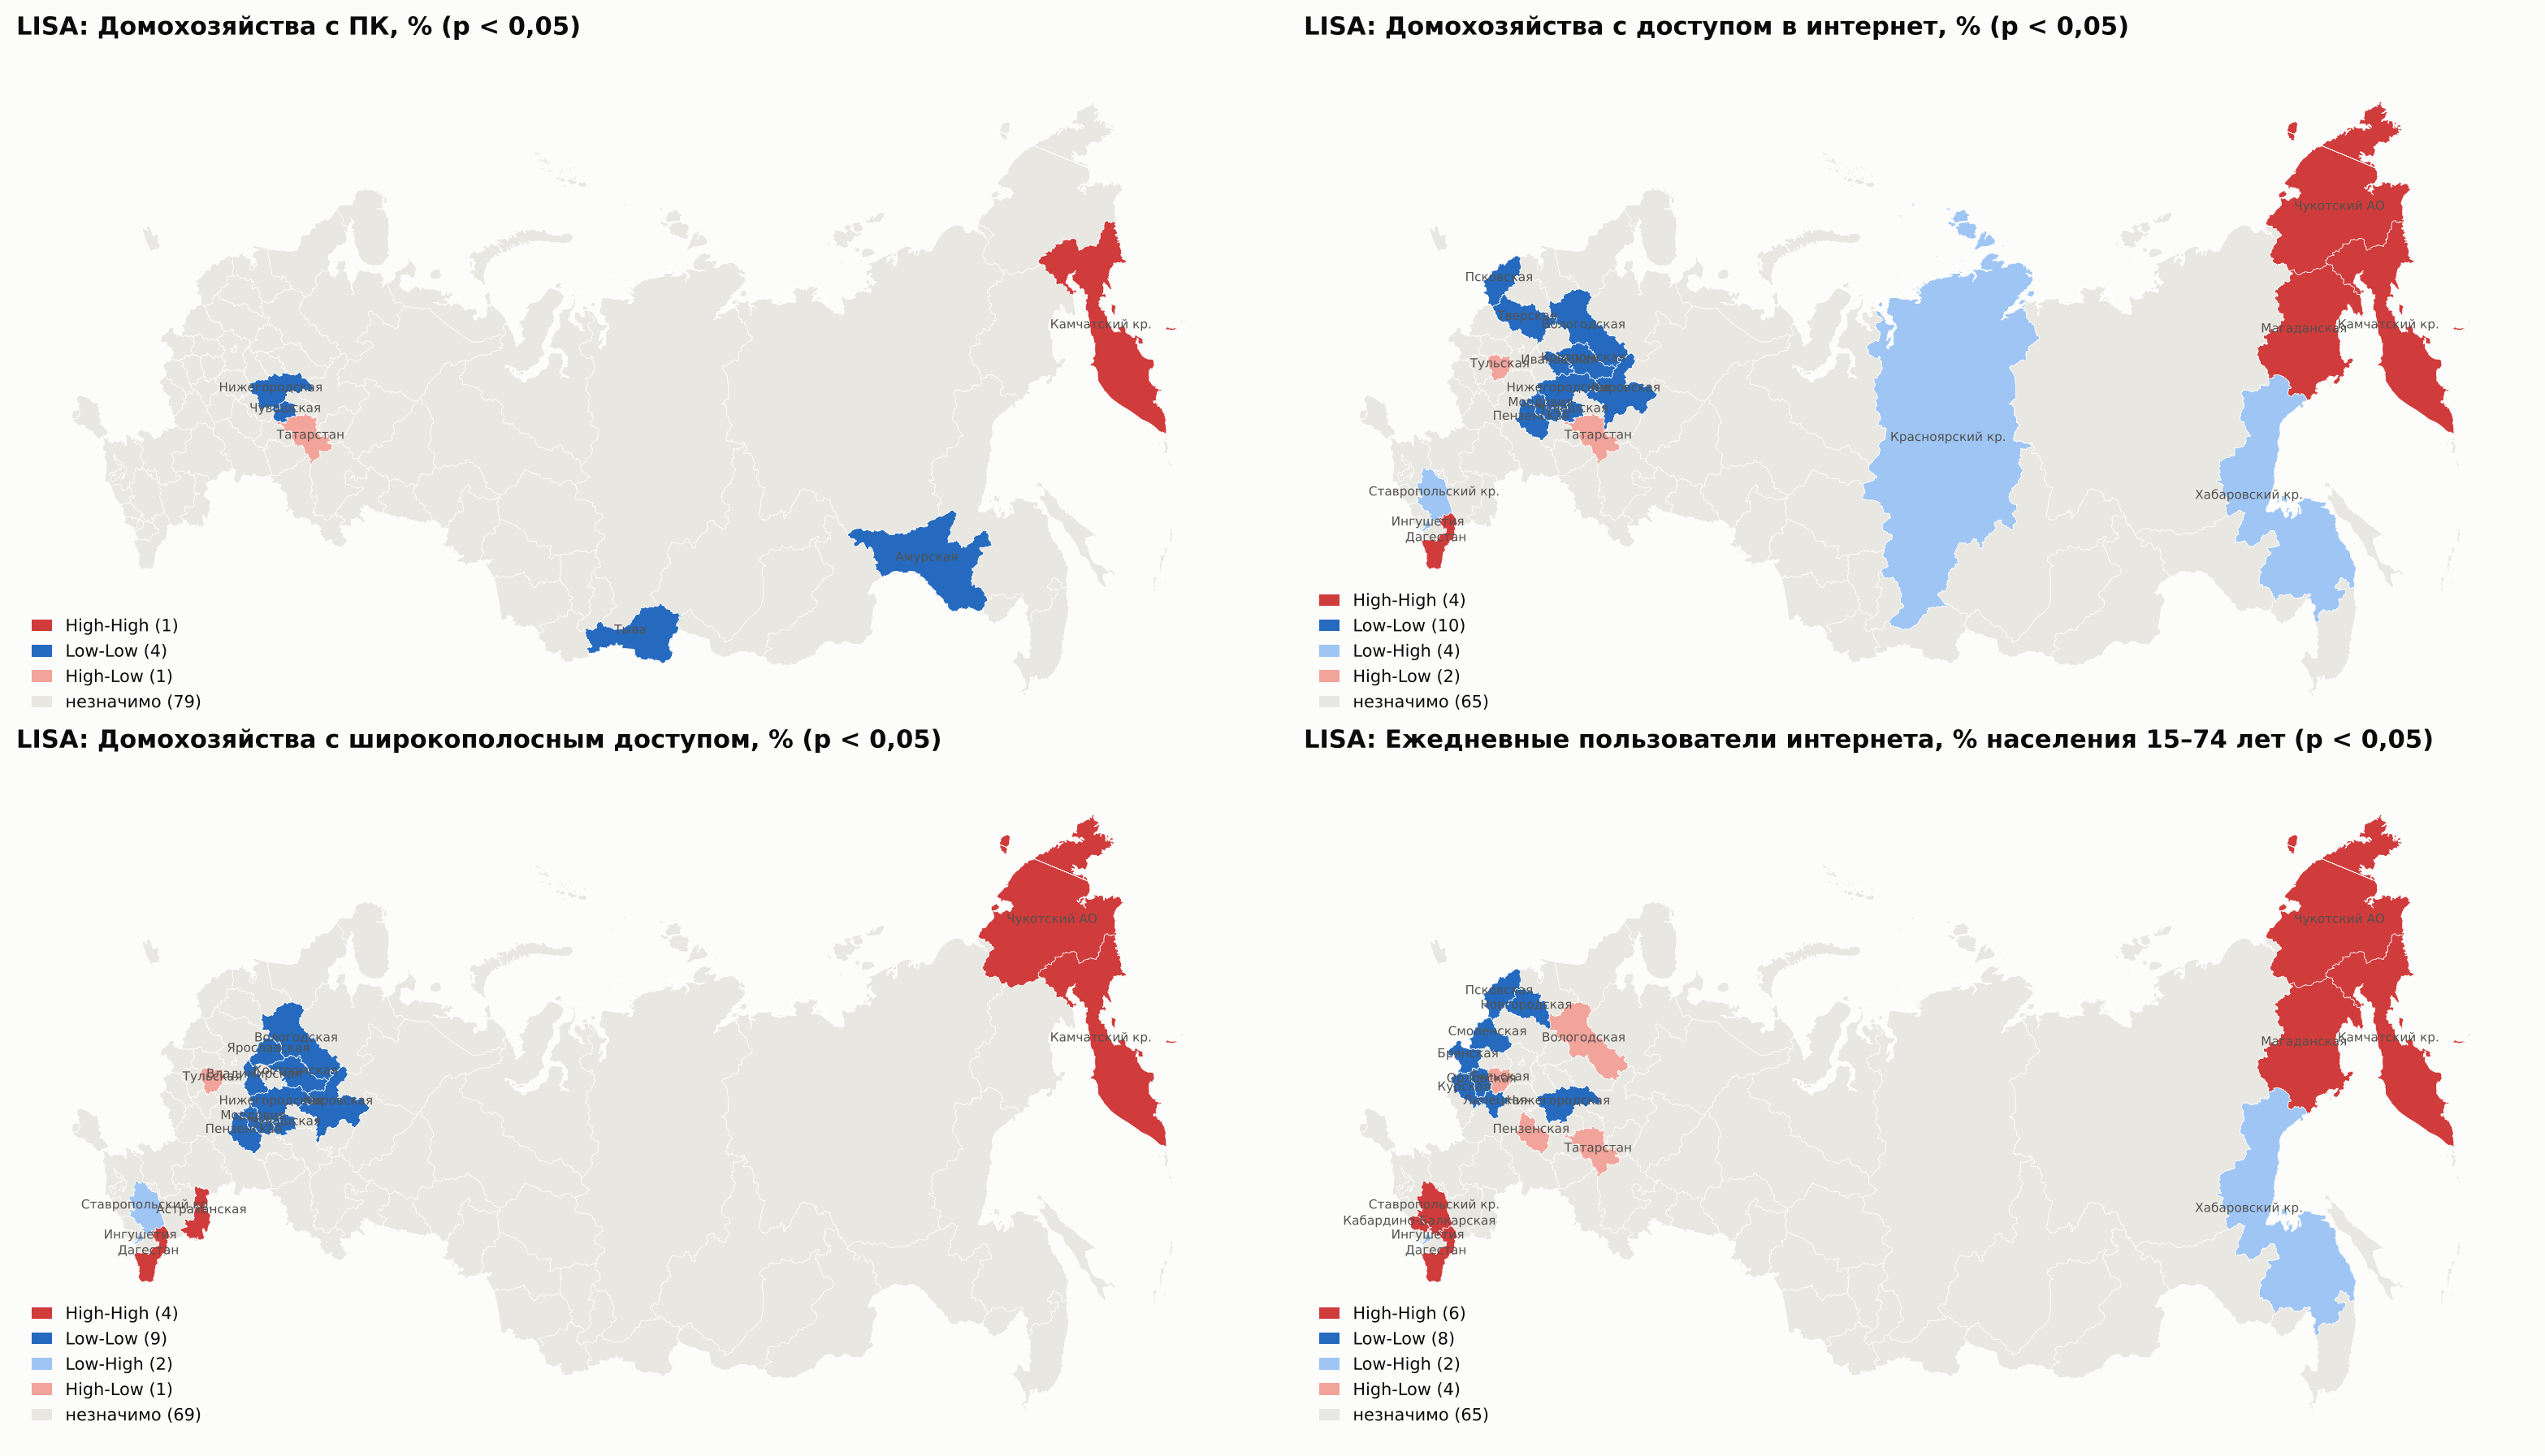

,незначимо,Low-Low,High-High,High-Low,значимо после FDR,Low-High
показатель,,,,,,
ПК,79,4,1,1,0,0.0
Интернет,65,10,4,2,4,4.0
ШПД,69,9,4,1,3,2.0
Ежедневно онлайн,65,8,6,4,1,2.0


In [10]:
lisas, lisa_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, f in zip(axes.ravel(), FEATURES):
    li = esda.Moran_Local(X[f], W["Queen + связи"], permutations=9999, seed=SEED)
    lisas[f] = li
    cat = lisa_map(ax, gdf, li, title=f"LISA: {LABELS[f]} (p < 0,05)")
    fdr_thr = esda.fdr(li.p_sim, 0.05)
    lisa_rows.append({"показатель": SHORT[f], **pd.Series(cat).value_counts().to_dict(),
                      "значимо после FDR": int((li.p_sim <= fdr_thr).sum()) if fdr_thr else 0})
plt.tight_layout(); plt.savefig(MAPS / "02_lisa_maps.png", dpi=150, bbox_inches="tight"); plt.show()
lisa_tab = pd.DataFrame(lisa_rows).fillna(0).set_index("показатель")
lisa_tab.to_csv(RESULTS / "02_lisa_counts.csv", encoding="utf-8")
lisa_tab

Многомерный локальный индекс Гири (Anselin, 2019) $c_i=\frac1p\sum_{v=1}^{p}\sum_j w_{ij}(z_{vi}-z_{vj})^2$
измеряет, насколько регион отличается от соседей сразу по всем четырем стандартизованным признакам.
Малое значимое $c_i$ — регион похож на окружение (однородная зона), большое — граница между зонами.
Это прямая проверка, есть ли смысл в пространственно связных кластерах.

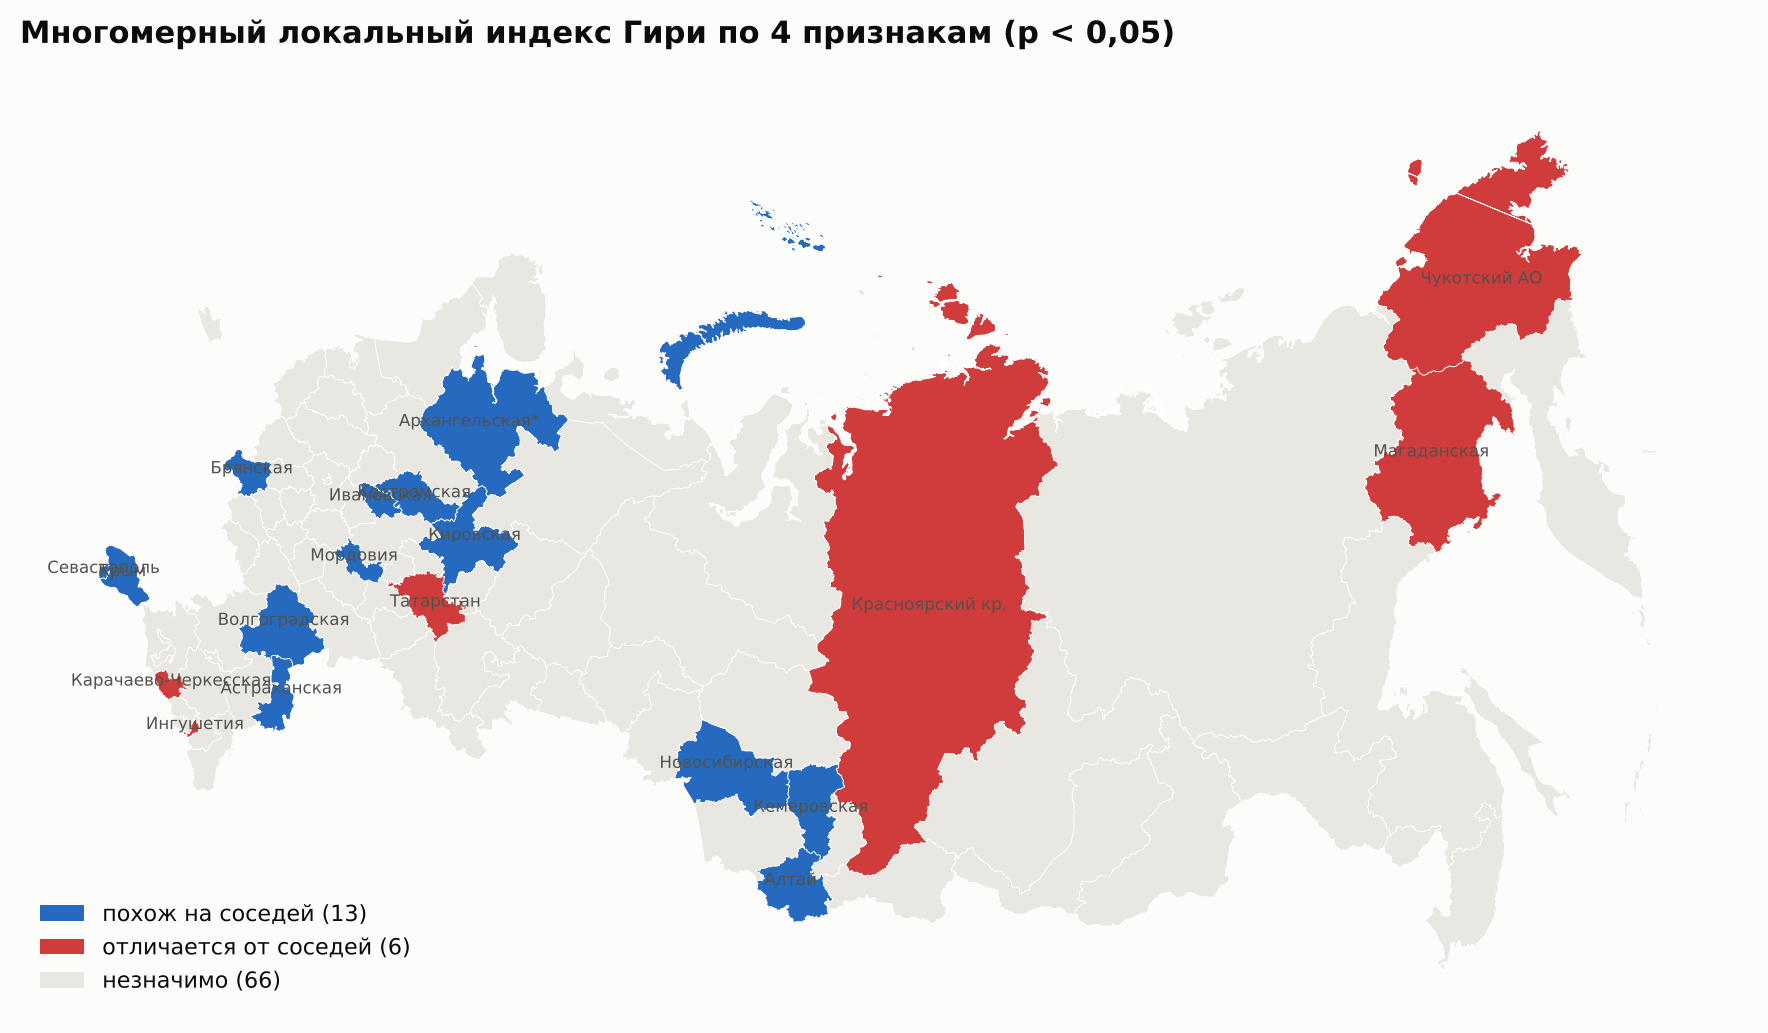

{'незначимо': 66, 'похож на соседей': 13, 'отличается от соседей': 6}


In [11]:
Z = StandardScaler().fit_transform(X)
gmv = esda.Geary_Local_MV(connectivity=W["Queen + связи"], permutations=9999).fit([Z[:, j] for j in range(4)])
gdf["geary_mv"] = gmv.localG
gdf["geary_mv_p"] = gmv.p_sim
sig = gdf.geary_mv_p < 0.05
med = np.median(gmv.localG)
kind = np.where(~sig, "незначимо", np.where(gmv.localG < med, "похож на соседей", "отличается от соседей"))
fig, ax = plt.subplots(figsize=(12, 6))
col = {"похож на соседей": BLUE, "отличается от соседей": RED, "незначимо": "#e8e7e2"}
gdf.plot(ax=ax, color=[col[k] for k in kind], edgecolor="#ffffff", linewidth=0.3)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=col[k], label=f"{k} ({int((kind == k).sum())})") for k in col], loc="lower left", fontsize=8)
for (_, r), k in zip(gdf.iterrows(), kind):
    if k != "незначимо":
        pt = r.geometry.representative_point(); ax.annotate(short_name(r["name"]), (pt.x, pt.y), fontsize=6, ha="center", color=INK2)
ax.set_axis_off(); ax.set_title("Многомерный локальный индекс Гири по 4 признакам (p < 0,05)", loc="left")
plt.savefig(MAPS / "02_geary_mv.png", dpi=150, bbox_inches="tight"); plt.show()
print(pd.Series(kind).value_counts().to_dict())

## 6. Связь признаков и выбор преобразования
Четыре показателя измеряют близкие стороны одного явления, поэтому проверяется их корреляция:
сильно коррелированные признаки при евклидовом расстоянии фактически получают повышенный вес.

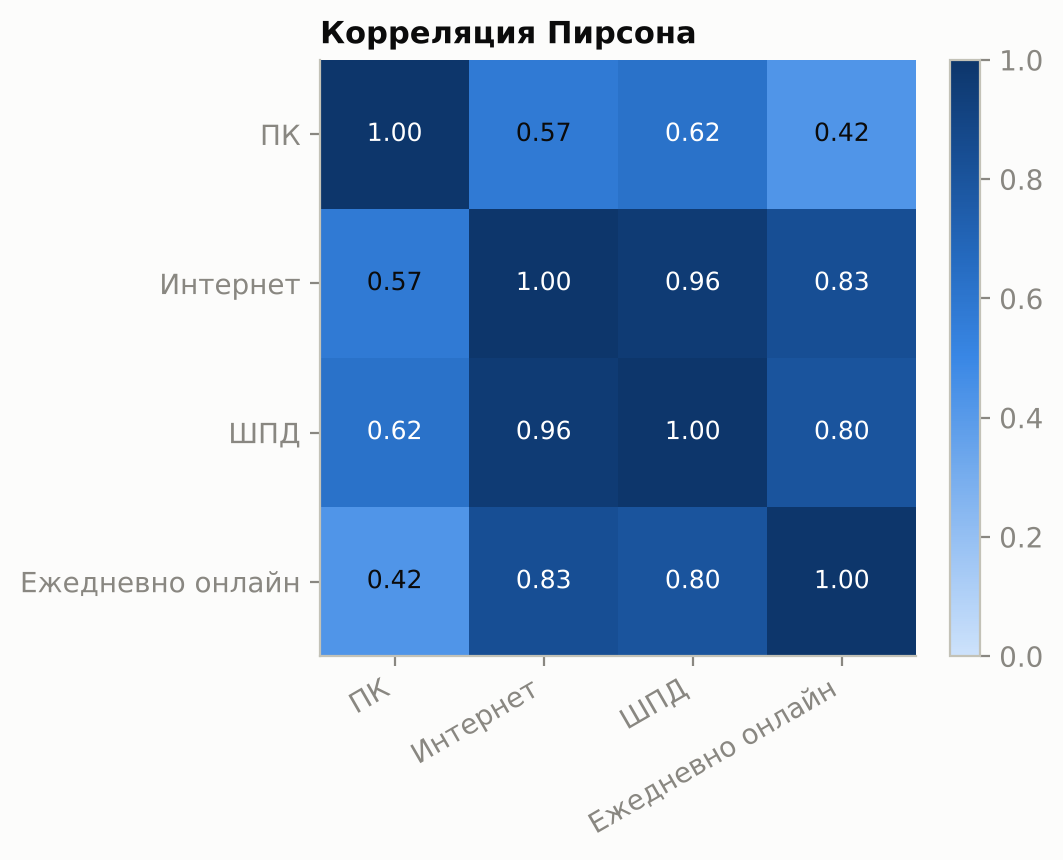

Спирмен:
                 pc  internet  broadband  daily_users
pc           1.000     0.535      0.564        0.356
internet     0.535     1.000      0.969        0.802
broadband    0.564     0.969      1.000        0.783
daily_users  0.356     0.802      0.783        1.000


In [12]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(corr, cmap=SEQ, vmin=0, vmax=1)
ax.set_xticks(range(4), [SHORT[f] for f in FEATURES], rotation=30, ha="right")
ax.set_yticks(range(4), [SHORT[f] for f in FEATURES]); ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="#ffffff" if corr.iloc[i, j] > 0.6 else "#0b0b0b", fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Корреляция Пирсона", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "02_correlation.png", dpi=150, bbox_inches="tight"); plt.show()
print("Спирмен:\n", X.corr("spearman").round(3))

In [13]:
pca = PCA().fit(Z)
load = pd.DataFrame(pca.components_.T, index=[SHORT[f] for f in FEATURES], columns=[f"PC{i+1}" for i in range(4)])
print("доля объясненной дисперсии:", pca.explained_variance_ratio_.round(3), "| накопленная:", pca.explained_variance_ratio_.cumsum().round(3))
load.round(3)

доля объясненной дисперсии: [0.785 0.156 0.05  0.009] | накопленная: [0.785 0.941 0.991 1.   ]


,PC1,PC2,PC3,PC4
ПК,0.401,0.879,0.253,0.046
Интернет,0.545,-0.175,-0.387,0.723
ШПД,0.545,-0.076,-0.478,-0.685
Ежедневно онлайн,0.495,-0.437,0.747,-0.079


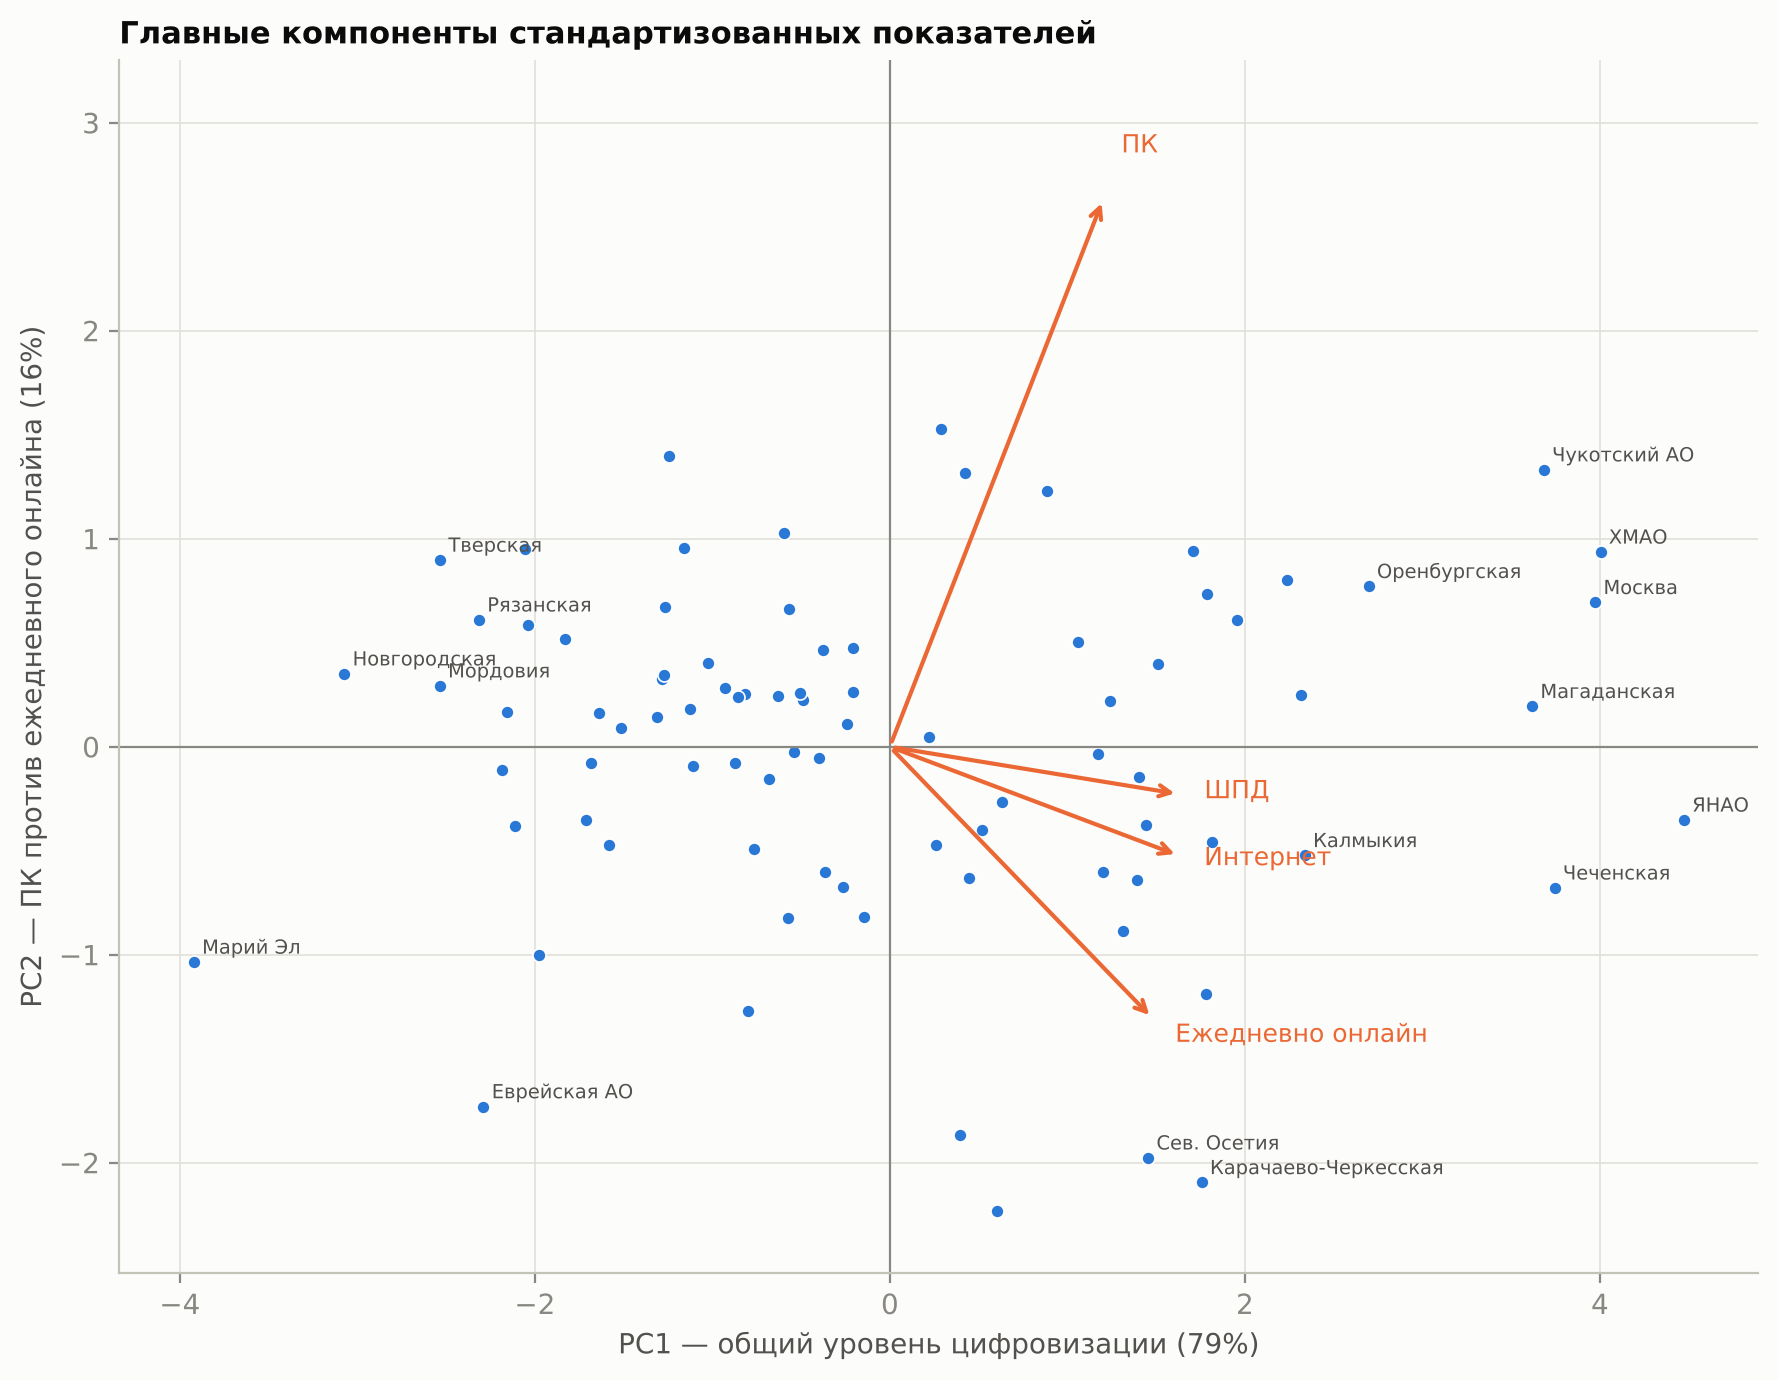

In [14]:
scores = pca.transform(Z)
gdf["PC1"], gdf["PC2"] = scores[:, 0], scores[:, 1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(gdf.PC1, gdf.PC2, s=22, color=CAT[0], edgecolor="#ffffff", linewidth=0.6)
for i in np.argsort(-(gdf.PC1 ** 2 + gdf.PC2 ** 2).to_numpy())[:16]:
    ax.annotate(short_name(gdf.name[i]), (gdf.PC1[i], gdf.PC2[i]), fontsize=7, color=INK2, xytext=(3, 3), textcoords="offset points")
for j, f in enumerate(FEATURES):
    ax.annotate("", xy=(3 * pca.components_[0, j], 3 * pca.components_[1, j]), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=CAT[1], lw=1.5))
    ax.text(3.25 * pca.components_[0, j], 3.25 * pca.components_[1, j], SHORT[f], color=CAT[1], fontsize=9)
ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
ax.set_ylim(min(gdf.PC2.min(), 3.3 * pca.components_[1].min()) - 0.3, max(gdf.PC2.max(), 3.3 * pca.components_[1].max()) + 0.4)
ax.set_xlabel(f"PC1 — общий уровень цифровизации ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 — ПК против ежедневного онлайна ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Главные компоненты стандартизованных показателей", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "02_pca_biplot.png", dpi=150, bbox_inches="tight"); plt.show()

In [15]:
for pc in ["PC1", "PC2"]:
    mi = esda.Moran(gdf[pc], W["Queen + связи"], permutations=9999)
    print(f"Moran's I {pc}: {mi.I:.3f}, p = {mi.p_sim:.4f}")

Moran's I PC1: 0.233, p = 0.0019
Moran's I PC2: 0.246, p = 0.0012


## 7. Выбросы
Регионы с |z| > 2,5 хотя бы по одному признаку и расстояние Махаланобиса (учитывает корреляцию признаков;
при многомерной нормальности $D^2\sim\chi^2_4$, порог 0,99-квантиль = 13,3).

In [16]:
zdf = pd.DataFrame(Z, columns=[SHORT[f] for f in FEATURES], index=gdf.name)
S_inv = np.linalg.inv(np.cov(Z.T))
d2 = np.einsum("ij,jk,ik->i", Z, S_inv, Z)
out = zdf.assign(D2=d2)[(zdf.abs() > 2.5).any(axis=1) | (d2 > stats.chi2.ppf(0.99, 4))]
out.round(2).sort_values("D2", ascending=False)

,ПК,Интернет,ШПД,Ежедневно онлайн,D2
name,,,,,
Республика Саха (Якутия),-0.32,1.77,0.59,1.26,19.39
Еврейская автономная область,-2.29,-0.78,-1.70,-0.04,14.52
Чукотский автономный округ,2.79,1.64,1.59,1.62,8.69
Ханты-Мансийский автономный округ – Югра,2.55,1.77,1.93,1.94,7.77
Республика Марий Эл,-2.59,-1.84,-1.82,-1.79,7.46
Ямало-Ненецкий автономный округ,1.45,2.47,2.59,2.29,6.83


## 8. Выводы диагностики
Итоговые числа — в таблицах выше и в `results/`. Решения для кластеризации:
- **Структура соседства** — Queen-смежность с присоединением изолированных регионов; результаты Морана
  устойчивы к замене на KNN (знак и значимость сохраняются), а связный граф нужен регионализационным методам.
- **Преобразование признаков** — стандартизация (z-оценки): показатели в процентах, но по разной базе
  (домохозяйства и население) и с разным разбросом. Логарифм не нужен: асимметрия мала.
- **Избыточность** — интернет и ШПД коррелируют почти полностью, первая главная компонента объясняет
  большую часть дисперсии. Основное пространство признаков — 4 z-оценки (интерпретируемость),
  проверка устойчивости — пространство двух первых главных компонент.
- **Выбросы** (ЯНАО, Чукотка, Чечня, Москва) не удаляются: это реальные регионы с особым профилем; методы,
  чувствительные к выбросам (k-средние), сравниваются с иерархическими.

In [17]:
gdf.drop(columns="geometry").to_csv(RESULTS / "02_regions_with_pca_geary.csv", index=False, encoding="utf-8")